In [9]:
import pandas as pd
#DATA UNDERSTANDING AND GRAPHS
import pandas as pd
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import seaborn as sns


import pickle

# DATA PREPARATION
import nltk
from nltk.tokenize import word_tokenize
from nltk.tag import pos_tag
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
import re
import ast
from collections import Counter

from nltk.util import ngrams
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet


# OUR FUNCTIONS
from utils.visualizations import get_clean_words, extract_words
from langdetect import detect
from utils.functions_eda_preproc import verify_language, clean_text, normalize_text

import os
import pickle
import re
import nltk
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import plotly.express as px
from collections import Counter, defaultdict
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score, precision_score, recall_score
from tqdm import tqdm
from wordcloud import WordCloud
from mittens import GloVe
from gensim.models import Word2Vec
import utils.visualizations as visualizations
import importlib
importlib.reload(visualizations)
from utils.visualizations import word_cloud_generator, show_saved_images,cooccurrence_matrix_sentence_generator, plot_genre_cooccurrence, d2_embeddings_plotter

from sklearn.naive_bayes import ComplementNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.naive_bayes import MultinomialNB
!pip install scikit-learn
from sklearn.naive_bayes import MultinomialNB


from utils.functions_vectors_modelling import evaluate_models, document_vector
import warnings
warnings.filterwarnings('ignore')


In [2]:
train = pd.read_csv('./Datasets/train.csv', index_col = 'id')
test = pd.read_csv('./Datasets/test.csv',index_col = 'id')
train.head()

,title,tag,artist,year,views,features,lyrics
id,,,,,,,
535805,Walk Away,rock,Tony Molina,2013,699,{},When you said you loved me\r\nDid you mean it ...
7519483,Gotta Make It Kid Naruto Rap,rap,Reece Lett,2021,4,{Sl!ck},Kid Naruto Rap\r\n[Hook]\r\nEverybody wants yo...
4892808,​this is what i asked for,pop,Elliot (DNK),2019,389,{},[Verse 1]\r\nPeople tell me I've changed\r\nI ...
1584150,Stealing Hearts,pop,Katie Armiger,2013,126,{},You've been warned about me\r\nDon't try to ge...
7639050,Get Ready,country,John Campbell Munro,1,2,{},[Verse 1]\r\nI can see the end is coming but I...


In [3]:
train = train.rename(columns={'lyrics': 'raw_lyrics'})
test = test.rename(columns={'lyrics': 'raw_lyrics'})


In [4]:
train['lyrics_cleaned']= clean_text(train, 'raw_lyrics',
                                      emojis=True, hashtags=True, mentions=True,
                                      urls=True, html_tags=True, square_brackets=True,
                                      newlines=True, punctuation=True, apostrophes=True, whitespaces=True)

In [5]:
test['lyrics_cleaned']= clean_text(test, 'raw_lyrics',
                                      emojis=True, hashtags=True, mentions=True,
                                      urls=True, html_tags=True, square_brackets=True,
                                      newlines=True, punctuation=True, whitespaces=True)

In [6]:
train

,title,tag,artist,year,views,features,raw_lyrics,lyrics_cleaned
id,,,,,,,,
535805,Walk Away,rock,Tony Molina,2013,699,{},When you said you loved me\r\nDid you mean it ...,When you said you loved me Did you mean it the...
7519483,Gotta Make It Kid Naruto Rap,rap,Reece Lett,2021,4,{Sl!ck},Kid Naruto Rap\r\n[Hook]\r\nEverybody wants yo...,Kid Naruto Rap Everybody wants you to hurt Eve...
4892808,​this is what i asked for,pop,Elliot (DNK),2019,389,{},[Verse 1]\r\nPeople tell me I've changed\r\nI ...,People tell me Ive changed I find it hard to e...
1584150,Stealing Hearts,pop,Katie Armiger,2013,126,{},You've been warned about me\r\nDon't try to ge...,Youve been warned about me Dont try to get too...
7639050,Get Ready,country,John Campbell Munro,1,2,{},[Verse 1]\r\nI can see the end is coming but I...,I can see the end is coming but I ve never lik...
...,...,...,...,...,...,...,...,...
1702980,Manhattan,pop,Tijuana Sweetheart,2007,48,{},If I knew when I was young that I'd be older\r...,If I knew when I was young that Id be older Th...
4802970,Belly Shit,rap,Lil Gotit,2019,3593,"{""Lil Troup""}",[Intro: Lil Gotit]\r\nCash\r\nWah-wah-wah\r\nW...,Cash Wah wah wah Wah wah wah Everything is chr...
403929,The Four Loves,rock,Heath McNease,2014,301,{},[Verse 1]\r\nI was born inside a home\r\nThe y...,I was born inside a home The youngest of the t...


In [7]:
train['lyrics_normalized'] = train['lyrics_cleaned'].apply(
    lambda x: normalize_text(
        x, 
        custom_stopwords= None,
        tokenized_output=False))

In [8]:
test['lyrics_normalized'] = test['lyrics_cleaned'].apply(
    lambda x: normalize_text(x,
        custom_stopwords= None,
        tokenized_output=False))

In [10]:
X = train["lyrics_normalized"].fillna("").astype(str)
y = train["tag"]

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print(f"Training subset: {len(X_train):,} songs")
print(f"Validation subset: {len(X_val):,} songs")

Training subset: 107,973 songs
Validation subset: 26,994 songs


In [12]:
import pandas as pd
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

def evaluate_models(X_train_vec, X_test_vec, y_train, y_test, representation_name):
    models = {
        'Naive Bayes': MultinomialNB(),
        'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
        'SGD Classifier (SVM)': SGDClassifier(class_weight='balanced', loss='hinge', max_iter=1000, random_state=42),
        'Random Forest': RandomForestClassifier(class_weight='balanced', n_estimators=50, random_state=42, n_jobs=-1)
    }
    
    results = []
    
    for name, model in models.items():
        # Verifica valores negativos de forma segura tanto em matrizes esparsas (BoW/TF-IDF) como densas (Word2Vec/GloVe)
        has_negative = (X_train_vec < 0).nnz > 0 if hasattr(X_train_vec, "nnz") else (X_train_vec < 0).any()
        if name == 'Naive Bayes' and has_negative:
            print(f"A saltar {name} (não aceita valores negativos nas representações densas).")
            continue
            
        print(f"Training {name} with {representation_name}...")
        model.fit(X_train_vec, y_train)
        preds = model.predict(X_test_vec)
      
        score = f1_score(y_test, preds, average='macro')
        
        results.append({
            'Representation': representation_name,
            'Model': name,
            'Macro F1-Score': round(score, 4)
        })
        
    return pd.DataFrame(results).sort_values(by='Macro F1-Score', ascending=False)

In [13]:
bow_vectorizer = CountVectorizer(
    ngram_range=(1, 2), 
    token_pattern=r"(?u)\b\w+\b",
    min_df=5,
    max_features=10000,
)


X_train_bow = bow_vectorizer.fit_transform(X_train)
X_val_bow = bow_vectorizer.transform(X_val)


results_bow = evaluate_models(X_train_bow, X_val_bow, y_train, y_val, "Bag of Words")
display(results_bow)

Training Naive Bayes with Bag of Words...
Training Logistic Regression with Bag of Words...
Training SGD Classifier (SVM) with Bag of Words...
Training Random Forest with Bag of Words...


,Representation,Model,Macro F1-Score
0,Bag of Words,Naive Bayes,0.4375
2,Bag of Words,SGD Classifier (SVM),0.4197
1,Bag of Words,Logistic Regression,0.4026
3,Bag of Words,Random Forest,0.3748


In [14]:
tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 3),
    token_pattern=r"(?u)\b\w+\b",
    min_df=5,
    max_features=10000,
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_val_tfidf = tfidf_vectorizer.transform(X_val)


results_tfidf = evaluate_models(X_train_tfidf, X_val_tfidf, y_train, y_val, "TF-IDF")
display(results_tfidf)

Training Naive Bayes with TF-IDF...
Training Logistic Regression with TF-IDF...
Training SGD Classifier (SVM) with TF-IDF...
Training Random Forest with TF-IDF...


,Representation,Model,Macro F1-Score
1,TF-IDF,Logistic Regression,0.4473
2,TF-IDF,SGD Classifier (SVM),0.4042
0,TF-IDF,Naive Bayes,0.3995
3,TF-IDF,Random Forest,0.3706


In [15]:
words_train = [lyric.split() for lyric in X_train]
words_val = [lyric.split() for lyric in X_val]

In [16]:
w2v_skipgram = Word2Vec(
    sentences= words_train,
    vector_size=100, 
    window=6, 
    min_count=5, 
    sg=1, 
    workers=4)

X_train_skip = np.array([document_vector(w2v_skipgram.wv, doc) for doc in words_train])
X_val_skip = np.array([document_vector(w2v_skipgram.wv, doc) for doc in words_val])

results_skip = evaluate_models(X_train_skip, X_val_skip, y_train, y_val, "Word2Vec Skip-gram")
display(results_skip)

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

A saltar Naive Bayes (não aceita valores negativos nas representações densas).
Training Logistic Regression with Word2Vec Skip-gram...
Training SGD Classifier (SVM) with Word2Vec Skip-gram...
Training Random Forest with Word2Vec Skip-gram...


,Representation,Model,Macro F1-Score
0,Word2Vec Skip-gram,Logistic Regression,0.4075
2,Word2Vec Skip-gram,Random Forest,0.4028
1,Word2Vec Skip-gram,SGD Classifier (SVM),0.3882


In [17]:
w2v_cbow = Word2Vec(
    sentences= words_train, 
    vector_size=100,
    window=6,
    min_count=5,
    sg=0,
    workers=4)

X_train_cbow = np.array([document_vector(w2v_cbow.wv, doc) for doc in words_train])
X_val_cbow = np.array([document_vector(w2v_cbow.wv, doc) for doc in words_val])

results_cbow = evaluate_models(X_train_cbow, X_val_cbow, y_train, y_val, "Word2Vec CBOW")
display(results_cbow)

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


A saltar Naive Bayes (não aceita valores negativos nas representações densas).
Training Logistic Regression with Word2Vec CBOW...
Training SGD Classifier (SVM) with Word2Vec CBOW...
Training Random Forest with Word2Vec CBOW...


,Representation,Model,Macro F1-Score
0,Word2Vec CBOW,Logistic Regression,0.3986
2,Word2Vec CBOW,Random Forest,0.3972
1,Word2Vec CBOW,SGD Classifier (SVM),0.3604


In [18]:
# A global co-occurrence matrix for GloVe
# Each row is a lyric; each pair of words within the context window adds a count.
max_vocab_size = 520
window_size = 8

# Learn the vocabulary and GloVe embeddings from the internal training split only.
lyrics = X_train.astype(str)
word_counts = Counter(
    word
    for lyric in lyrics
    for word in lyric.split()
)
cooccurrence_vocab = [word for word, _ in word_counts.most_common(max_vocab_size)]
word_to_id = {word: index for index, word in enumerate(cooccurrence_vocab)}

# Keep a small dense matrix so it can be passed directly to GloVe.
cooccurrence_matrix = np.zeros(
    (len(cooccurrence_vocab), len(cooccurrence_vocab)),
    dtype=np.float64,
)

for lyric in tqdm(lyrics, desc="Counting global word co-occurrences"):
    tokens = lyric.split()
    for position, word in enumerate(tokens):
        word_id = word_to_id.get(word)
        if word_id is None:
            continue

        # Look at the next words within the context window and update both directions.
        end = min(position + window_size + 1, len(tokens))
        for context_word in tokens[position + 1:end]:
            context_id = word_to_id.get(context_word)
            if context_id is not None and context_id != word_id:
                cooccurrence_matrix[word_id, context_id] += 1
                cooccurrence_matrix[context_id, word_id] += 1

# DataFrame view for inspection; the NumPy array is what GloVe will consume.
cooccurrence_df = pd.DataFrame(
    cooccurrence_matrix,
    index=cooccurrence_vocab,
    columns=cooccurrence_vocab,
)

print(f"Matrix shape: {cooccurrence_matrix.shape}")
print(f"Vocabulary size: {len(cooccurrence_vocab)}")
cooccurrence_df.iloc[:10, :10]

Counting global word co-occurrences: 100%|██████████| 107973/107973 [02:40<00:00, 671.58it/s]

Matrix shape: (520, 520)
Vocabulary size: 520


,get,like,go,know,want,love,say,yeah,make,see
get,0.0,76812.0,77448.0,75990.0,59434.0,37007.0,39380.0,50857.0,34777.0,29390.0
like,76812.0,0.0,40290.0,45569.0,35618.0,27836.0,25380.0,28839.0,25561.0,21878.0
go,77448.0,40290.0,0.0,59103.0,41410.0,29461.0,31508.0,27172.0,27036.0,21986.0
know,75990.0,45569.0,59103.0,0.0,51025.0,38591.0,33588.0,32017.0,23578.0,25206.0
want,59434.0,35618.0,41410.0,51025.0,0.0,33671.0,27532.0,25922.0,23038.0,24686.0
love,37007.0,27836.0,29461.0,38591.0,33671.0,0.0,24391.0,19573.0,20402.0,13785.0
say,39380.0,25380.0,31508.0,33588.0,27532.0,24391.0,0.0,15819.0,15602.0,12936.0
yeah,50857.0,28839.0,27172.0,32017.0,25922.0,19573.0,15819.0,0.0,13409.0,10683.0
make,34777.0,25561.0,27036.0,23578.0,23038.0,20402.0,15602.0,13409.0,0.0,11725.0
see,29390.0,21878.0,21986.0,25206.0,24686.0,13785.0,12936.0,10683.0,11725.0,0.0


In [19]:
glove_model = GloVe(n=50, max_iter=500, display_progress=10)
embeddings = glove_model.fit(cooccurrence_df.to_numpy())

glove_lookup = dict(zip(cooccurrence_vocab, embeddings))

# 3. A TUA função antiga de fazer a média por música!
def average_glove_vectors(texts):
    glove_vector_size = len(next(iter(glove_lookup.values())))
    document_vectors = []
    
    for text in texts.astype(str):
        # Vai buscar os vetores ao dicionário que acabaste de criar
        vectors = [glove_lookup[token] for token in text.split() if token in glove_lookup]
        if vectors:
            document_vectors.append(np.mean(vectors, axis=0))
        else:
            document_vectors.append(np.zeros(glove_vector_size))
            
    return np.vstack(document_vectors)

# 4. Gerar matrizes para o SGDClassifier
X_train_glove_custom = average_glove_vectors(X_train)
X_val_glove_custom = average_glove_vectors(X_val)

# 5. Avaliar na nossa tabela de F1-Scores!
results_glove_custom = evaluate_models(X_train_glove_custom, X_val_glove_custom, y_train, y_val, "GloVe Custom")
display(results_glove_custom)


Instructions for updating:
Call initializer instance with the dtype argument instead of passing it to the constructor



Iteration 500: loss: 11062.9794921875

A saltar Naive Bayes (não aceita valores negativos nas representações densas).
Training Logistic Regression with GloVe Custom...
Training SGD Classifier (SVM) with GloVe Custom...
Training Random Forest with GloVe Custom...


,Representation,Model,Macro F1-Score
2,GloVe Custom,Random Forest,0.3522
0,GloVe Custom,Logistic Regression,0.3401
1,GloVe Custom,SGD Classifier (SVM),0.3185


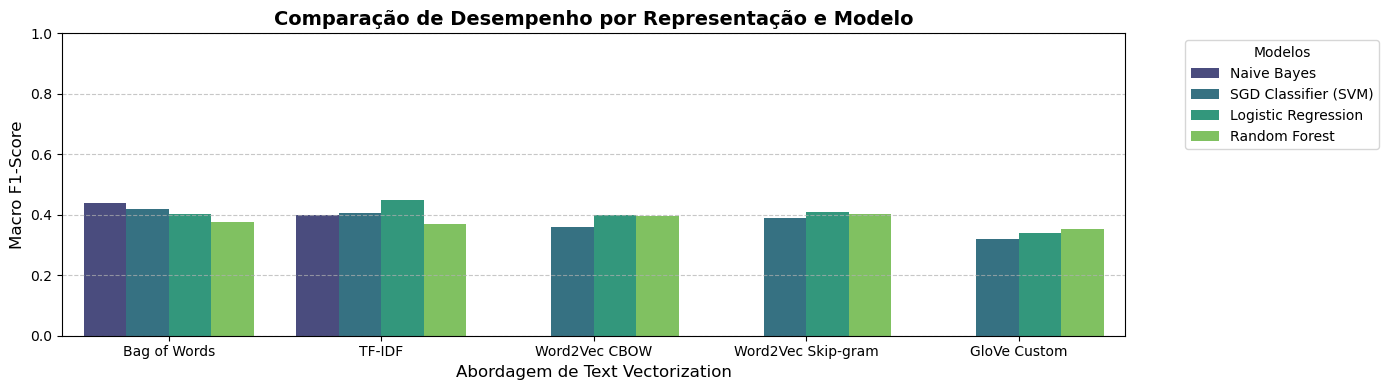

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

results_bow.columns = ['Representação', 'Model', 'Macro F1-Score']
results_tfidf.columns = ['Representação', 'Model', 'Macro F1-Score']
results_cbow.columns = ['Representação', 'Model', 'Macro F1-Score']
results_skip.columns = ['Representação', 'Model', 'Macro F1-Score']
results_glove_custom.columns = ['Representação', 'Model', 'Macro F1-Score']

# 2. Agora sim, juntar tudo sem erros
all_results = pd.concat([
    results_bow, 
    results_tfidf, 
    results_cbow, 
    results_skip, 
    results_glove_custom
], ignore_index=True)

# 2. Criar o gráfico de barras comparativo
plt.figure(figsize=(14, 4))
sns.barplot(
    data=all_results, 
    x='Representação', 
    y='Macro F1-Score', 
    hue='Model', 
    palette='viridis'
)

# 3. Formatação visual do gráfico para ficar profissional
plt.title('Comparação de Desempenho por Representação e Modelo', fontsize=14, fontweight='bold')
plt.xlabel('Abordagem de Text Vectorization', fontsize=12)
plt.ylabel('Macro F1-Score', fontsize=12)
plt.ylim(0, 1.0) # O F1-Score vai de 0 a 1
plt.legend(title='Modelos', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

plt.show()

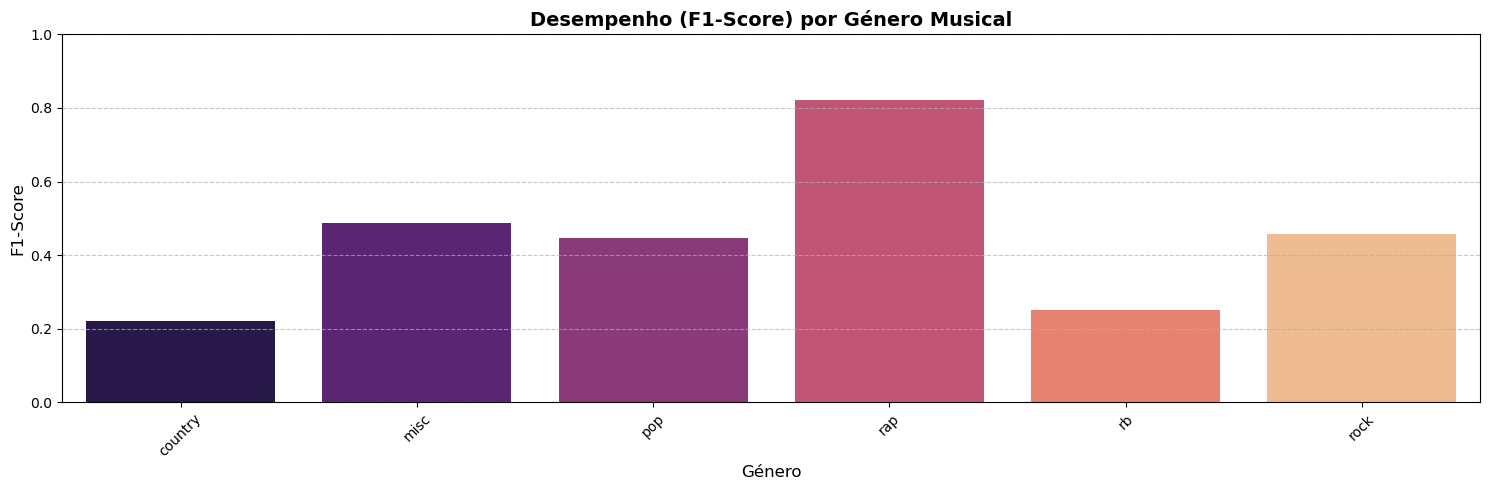

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression

# Exemplo rápido com o TF-IDF e Regressão Logística
best_model = LogisticRegression(class_weight='balanced', max_iter=1000)
best_model.fit(X_train_tfidf, y_train)
y_pred = best_model.predict(X_val_tfidf)
# 1. Gerar o relatório em formato de dicionário
report_dict = classification_report(y_val, y_pred, output_dict=True)

# 2. Transformar num DataFrame (removendo as linhas globais como accuracy/macro avg)
genres = [k for k in report_dict.keys() if k not in ['accuracy', 'macro avg', 'weighted avg']]
f1_scores_per_genre = [report_dict[genre]['f1-score'] for genre in genres]

df_genres = pd.DataFrame({
    'Género Musical': genres,
    'F1-Score': f1_scores_per_genre
})

# 3. Desenhar o gráfico de barras
plt.figure(figsize=(15, 5))
sns.barplot(data=df_genres, x='Género Musical', y='F1-Score', palette='magma')
plt.title('Desempenho (F1-Score) por Género Musical', fontsize=14, fontweight='bold')
plt.xlabel('Género', fontsize=12)
plt.ylabel('F1-Score', fontsize=12)
plt.xticks(rotation=45)
plt.ylim(0, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.model_selection import GridSearchCV, train_test_split

# (Opcional, mas recomendado para não demorar horas) 
# Podes usar a amostra de 30% que testámos há bocadinho:
X_train_sample, _, y_train_sample, _ = train_test_split(
    X_train, y_train, train_size=0.40, random_state=42, stratify=y_train
)

# 1. Construir o Pipeline integrando a vetorização e o classificador
pipeline = Pipeline([
    ('vectorizer', TfidfVectorizer()),
    ('classifier', SGDClassifier(class_weight='balanced', max_iter=1000, random_state=42))
])

# 2. Definir a grelha alargada
param_grid = [
    {
        'vectorizer': [TfidfVectorizer(), CountVectorizer()],
        'vectorizer__max_df': [0.75, 0.85, 1.0],
        'vectorizer__min_df': [2, 5],
        'vectorizer__ngram_range': [(1, 1), (1, 2)],
        'classifier': [SGDClassifier(class_weight='balanced', max_iter=1000, random_state=42)],
        'classifier__loss': ['hinge', 'log_loss', 'modified_huber'],
        'classifier__alpha': [0.0001, 0.001, 0.01]
    },
    {
        'vectorizer': [TfidfVectorizer(), CountVectorizer()],
        'vectorizer__max_df': [0.75, 0.85, 1.0],
        'vectorizer__min_df': [2, 5],
        'vectorizer__ngram_range': [(1, 1), (1, 2)],
        'classifier': [LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)],
        'classifier__C': [0.1, 1.0, 10.0]
    }
]

# 3. Configurar o GridSearchCV com verbose=2 (aqui está o segredo para veres o progresso!)
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=3,
    n_jobs=-1,
    verbose=2   # <--- Alterado de 1 para 2 para cuspir detalhes linha a linha
)

# 4. Executar (usamos a amostra X_train_sample para ser rápido, ou X_train se quiseres os 100%)
grid_search.fit(X_train_sample, y_train_sample)

# 5. Revelar o vencedor
print("Melhor Macro F1-Score na Validação Cruzada:", round(grid_search.best_score_, 4))
print("\nMelhor Modelo e Hiperparâmetros encontrados:")
for param, value in grid_search.best_params_.items():
    print(f"  {param}: {value}")

Fitting 3 folds for each of 288 candidates, totalling 864 fits
Melhor Macro F1-Score na Validação Cruzada: 0.4855

Melhor Modelo e Hiperparâmetros encontrados:
  classifier: SGDClassifier(class_weight='balanced', random_state=42)
  classifier__alpha: 0.0001
  classifier__loss: log_loss
  vectorizer: TfidfVectorizer()
  vectorizer__max_df: 0.75
  vectorizer__min_df: 5
  vectorizer__ngram_range: (1, 2)
